# 10 — Toronto multi-day heat × Bike Share panel

## Purpose

Notebook 09 showed that a single heat-event day does not provide a strong enough
behavioral validation signal.

This notebook therefore expands the analysis into a **summer 2025 station-day
panel**.

The objective is to ask:

> Do Bike Share stations located in areas with larger modeled
> heat-conditioned accessibility loss systematically show different ridership
> responses on hotter days?

The panel combines:

- June–August 2025 Bike Share trip starts;
- daily and 15:00 weather at U of T;
- station-level activity;
- citywide Bike Share demand;
- weekday controls;
- local modeled accessibility loss from Notebook 07.

This remains an **exploratory observational analysis**.

It is not a causal heat-demand model and does not behaviorally calibrate λ.

**Kernel:** Python 3.12 - VoxCity

## 1. Imports and project paths

In [1]:
from pathlib import Path
import re
import zipfile

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

from scipy.spatial import cKDTree
from scipy.stats import spearmanr

HERE = Path.cwd().resolve()

if HERE.name == "notebooks_toronto_v02":
    PROJECT_ROOT = HERE.parent
elif (HERE / "notebooks_toronto_v02").exists():
    PROJECT_ROOT = HERE
else:
    PROJECT_ROOT = Path(
        "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
    )

TORONTO_DATA = PROJECT_ROOT / "data" / "toronto"
TORONTO_RAW = TORONTO_DATA / "raw"
TORONTO_INTERIM = TORONTO_DATA / "interim"
TORONTO_OUTPUTS = PROJECT_ROOT / "outputs" / "toronto"

BIKE_RAW = TORONTO_RAW / "bikeshare"
ACCESSIBILITY_DIR = TORONTO_OUTPUTS / "accessibility"

PANEL_OUTPUTS = (
    TORONTO_OUTPUTS
    / "bikeshare_panel"
)

PANEL_OUTPUTS.mkdir(
    parents=True,
    exist_ok=True,
)

ZIP_PATH = (
    BIKE_RAW
    / "bike_share_ridership_2025.zip"
)

ACCESS_GPKG = (
    ACCESSIBILITY_DIR
    / "toronto_origin_accessibility_absolute_vs_relative_lambda_005.gpkg"
)

print("Bike Share ZIP:", ZIP_PATH)
print("Accessibility:", ACCESS_GPKG)

Bike Share ZIP: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/raw/bikeshare/bike_share_ridership_2025.zip
Accessibility: /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/accessibility/toronto_origin_accessibility_absolute_vs_relative_lambda_005.gpkg


## 2. Analysis period

We use meteorological summer:

**1 June – 31 August 2025**

In [2]:
START_DATE = pd.Timestamp("2025-06-01")
END_DATE = pd.Timestamp("2025-08-31")

print(
    "Analysis period:",
    START_DATE.date(),
    "to",
    END_DATE.date(),
)

Analysis period: 2025-06-01 to 2025-08-31


## 3. Identify June, July, and August Bike Share files

In [3]:
if not ZIP_PATH.exists():
    raise FileNotFoundError(
        "2025 Bike Share ZIP not found. Run Notebook 08 first."
    )

with zipfile.ZipFile(
    ZIP_PATH,
    "r",
) as archive:

    csv_names = [
        name
        for name in archive.namelist()
        if name.lower().endswith(".csv")
    ]

month_patterns = {
    6: r"2025[-_ ]?0?6",
    7: r"2025[-_ ]?0?7",
    8: r"2025[-_ ]?0?8",
}

month_files = {}

for month, pattern in month_patterns.items():

    matches = [
        name
        for name in csv_names
        if re.search(
            pattern,
            name,
            flags=re.IGNORECASE,
        )
    ]

    if not matches:
        raise RuntimeError(
            f"Could not identify month {month} file."
        )

    month_files[month] = matches[0]

print(month_files)

{6: 'bikeshare_2025_06.csv', 7: 'bikeshare_2025_07.csv', 8: 'bikeshare_2025_08.csv'}


## 4. Read summer Bike Share files using the confirmed 2025 schema

In [4]:
EXPECTED_COLUMNS = [
    "Trip_Id",
    "Trip_Duration",
    "Start_Station_Id",
    "Start_Time",
    "Start_Station_Name",
    "End_Station_Id",
    "End_Time",
    "End_Station_Name",
    "Bike_Id",
    "User_Type",
    "Bike_Model",
]


def read_month(
    zip_path,
    member,
):

    with zipfile.ZipFile(
        zip_path,
        "r",
    ) as archive:

        with archive.open(
            member
        ) as handle:

            df = pd.read_csv(
                handle,
                encoding="cp1252",
                low_memory=False,
            )

    missing = [
        column
        for column in EXPECTED_COLUMNS
        if column not in df.columns
    ]

    if missing:
        raise RuntimeError(
            f"{member} missing columns: {missing}"
        )

    return df


summer_parts = []

for month in [6, 7, 8]:

    df = read_month(
        ZIP_PATH,
        month_files[month],
    )

    print(
        month,
        f"{len(df):,}",
    )

    summer_parts.append(
        df
    )

summer = pd.concat(
    summer_parts,
    ignore_index=True,
)

print(
    "Summer rows:",
    f"{len(summer):,}",
)

6 980,624
7 1,192,062
8 1,164,697
Summer rows: 3,337,383


## 5. Standardize trip fields

In [5]:
RENAME = {
    "Trip_Id": "trip_id",
    "Trip_Duration": "duration_seconds",
    "Start_Station_Id": "start_station_id",
    "Start_Time": "start_datetime",
    "Start_Station_Name": "start_station_name",
    "End_Station_Id": "end_station_id",
    "End_Time": "end_datetime",
    "End_Station_Name": "end_station_name",
    "Bike_Id": "bike_id",
    "User_Type": "user_type",
    "Bike_Model": "bike_model",
}

summer = summer.rename(
    columns=RENAME
)

summer["start_datetime"] = pd.to_datetime(
    summer["start_datetime"],
    errors="coerce",
)

summer["end_datetime"] = pd.to_datetime(
    summer["end_datetime"],
    errors="coerce",
)

summer["duration_seconds"] = pd.to_numeric(
    summer["duration_seconds"],
    errors="coerce",
)

summer["date"] = (
    summer[
        "start_datetime"
    ]
    .dt.normalize()
)

summer["hour"] = (
    summer[
        "start_datetime"
    ]
    .dt.hour
)

summer["weekday"] = (
    summer[
        "start_datetime"
    ]
    .dt.day_name()
)

summer[
    "start_station_id_join"
] = (
    summer[
        "start_station_id"
    ]
    .astype(str)
    .str.replace(
        r"\.0$",
        "",
        regex=True,
    )
    .str.strip()
)

summer = summer[
    summer["date"].between(
        START_DATE,
        END_DATE,
    )
].copy()

print(
    "Valid summer trips:",
    f"{len(summer):,}",
)

Valid summer trips: 3,337,383


## 6. Build citywide daily Bike Share activity

In [6]:
city_daily = (
    summer
    .groupby("date")
    .size()
    .rename("city_trips")
    .reset_index()
)

city_daily["weekday"] = (
    city_daily["date"]
    .dt.day_name()
)

display(
    city_daily.head()
)

,date,city_trips,weekday
0,2025-06-01,23778,Sunday
1,2025-06-02,28647,Monday
2,2025-06-03,33120,Tuesday
3,2025-06-04,33254,Wednesday
4,2025-06-05,27770,Thursday


## 7. Build station-day trip-start panel

In [7]:
station_day = (
    summer
    .groupby(
        [
            "start_station_id_join",
            "date",
        ]
    )
    .size()
    .rename("station_trips")
    .reset_index()
)

station_day["weekday"] = (
    station_day["date"]
    .dt.day_name()
)

print(
    "Station-day rows:",
    f"{len(station_day):,}",
)

Station-day rows: 80,504


## 8. Retrieve current Bike Share station coordinates via GBFS

Current station geometry is still used as a practical proxy.

Historical station geometry should be verified before publication.

In [8]:
GBFS_ROOT_CANDIDATES = [
    (
        "https://tor.publicbikesystem.net/"
        "ube/gbfs/v1/gbfs.json"
    ),
    (
        "https://tor.publicbikesystem.net/"
        "customer/gbfs/v2/gbfs.json"
    ),
]

gbfs_root = None

for candidate in GBFS_ROOT_CANDIDATES:

    try:

        r = requests.get(
            candidate,
            timeout=30,
        )

        if r.ok:
            gbfs_root = r.json()
            break

    except Exception:
        pass

if gbfs_root is None:
    raise RuntimeError(
        "GBFS feed unavailable."
    )

data_section = gbfs_root.get(
    "data",
    {}
)

if "en" in data_section:
    feeds = data_section["en"].get(
        "feeds",
        []
    )
else:
    feeds = data_section.get(
        "feeds",
        []
    )

station_info_url = None

for feed in feeds:

    if feed.get("name") == "station_information":
        station_info_url = feed.get("url")
        break

if station_info_url is None:
    raise RuntimeError(
        "station_information feed not found."
    )

station_json = requests.get(
    station_info_url,
    timeout=30,
).json()

station_df = pd.DataFrame(
    station_json["data"]["stations"]
)

station_df[
    "station_id_join"
] = (
    station_df["station_id"]
    .astype(str)
    .str.strip()
)

## 9. Load modeled accessibility loss

In [9]:
if not ACCESS_GPKG.exists():
    raise FileNotFoundError(
        "Notebook 07 accessibility output not found."
    )

origins = gpd.read_file(
    ACCESS_GPKG
)

for column in [
    "absolute_loss_pct",
    "relative_loss_pct",
]:
    origins[column] = pd.to_numeric(
        origins[column],
        errors="coerce",
    )

print(
    "Accessibility origins:",
    len(origins),
)

Accessibility origins: 50


## 10. Build station GeoDataFrame in accessibility CRS

In [10]:
stations = gpd.GeoDataFrame(
    station_df,
    geometry=gpd.points_from_xy(
        station_df["lon"],
        station_df["lat"],
    ),
    crs=4326,
).to_crs(
    origins.crs
)

print(
    "Current stations:",
    len(stations),
)

Current stations: 1072


## 11. Retain stations in the local accessibility pilot

The accessibility origins define the local study footprint.

In [11]:
pilot_polygon = (
    origins.geometry
    .union_all()
    .convex_hull
    .buffer(150)
)

pilot_stations = stations[
    stations.geometry.within(
        pilot_polygon
    )
    |
    stations.geometry.touches(
        pilot_polygon
    )
].copy()

print(
    "Pilot stations:",
    len(pilot_stations),
)

Pilot stations: 75


## 12. Interpolate local modeled accessibility loss to stations

We use inverse-distance weighting of the five nearest accessibility origins.

In [12]:
K_NEAREST = 5
EPSILON_M = 1.0

origin_xy = np.column_stack(
    [
        origins.geometry.x.to_numpy(),
        origins.geometry.y.to_numpy(),
    ]
)

station_xy = np.column_stack(
    [
        pilot_stations.geometry.x.to_numpy(),
        pilot_stations.geometry.y.to_numpy(),
    ]
)

tree = cKDTree(
    origin_xy
)

distances, indices = tree.query(
    station_xy,
    k=min(
        K_NEAREST,
        len(origins),
    ),
)

if distances.ndim == 1:
    distances = distances[:, None]
    indices = indices[:, None]

weights = 1.0 / (
    distances
    + EPSILON_M
)

weights = (
    weights
    / weights.sum(
        axis=1,
        keepdims=True,
    )
)

abs_values = (
    origins[
        "absolute_loss_pct"
    ]
    .to_numpy()
)

rel_values = (
    origins[
        "relative_loss_pct"
    ]
    .to_numpy()
)

pilot_stations[
    "modeled_absolute_loss_pct"
] = np.sum(
    weights
    * abs_values[indices],
    axis=1,
)

pilot_stations[
    "modeled_relative_loss_pct"
] = np.sum(
    weights
    * rel_values[indices],
    axis=1,
)

## 13. Build a complete pilot station-day panel

Missing station-days are explicitly represented as zero observed trip starts.

In [13]:
pilot_station_ids = (
    pilot_stations[
        "station_id_join"
    ]
    .astype(str)
    .tolist()
)

all_dates = pd.date_range(
    START_DATE,
    END_DATE,
    freq="D",
)

panel_index = pd.MultiIndex.from_product(
    [
        pilot_station_ids,
        all_dates,
    ],
    names=[
        "station_id_join",
        "date",
    ],
)

panel = (
    station_day
    .set_index(
        [
            "start_station_id_join",
            "date",
        ]
    )
    .rename_axis(
        index=[
            "station_id_join",
            "date",
        ]
    )
    .reindex(
        panel_index
    )
    .reset_index()
)

panel["station_trips"] = (
    panel["station_trips"]
    .fillna(0)
    .astype(int)
)

panel["weekday"] = (
    panel["date"]
    .dt.day_name()
)

print(
    "Complete panel rows:",
    len(panel),
)

Complete panel rows: 6900


## 14. Merge citywide activity

In [14]:
panel = panel.merge(
    city_daily[
        [
            "date",
            "city_trips",
        ]
    ],
    on="date",
    how="left",
)

## 15. Retrieve U of T historical weather for summer 2025

We use Open-Meteo historical hourly data at the U of T pilot center.

Variables:

- 2 m air temperature;
- relative humidity;
- 10 m wind speed;
- shortwave radiation.

This is a gridded historical reconstruction, not station observation.

In [15]:
campus_center = gpd.read_file(
    TORONTO_RAW
    / "toronto_uoft_center.gpkg"
).to_crs(4326)

LAT = float(
    campus_center.geometry.y.iloc[0]
)

LON = float(
    campus_center.geometry.x.iloc[0]
)

weather_url = (
    "https://archive-api.open-meteo.com/v1/archive"
)

weather_params = {
    "latitude": LAT,
    "longitude": LON,
    "start_date": START_DATE.date().isoformat(),
    "end_date": END_DATE.date().isoformat(),
    "hourly": (
        "temperature_2m,"
        "relative_humidity_2m,"
        "wind_speed_10m,"
        "shortwave_radiation"
    ),
    "timezone": "America/Toronto",
    "wind_speed_unit": "ms",
}

weather_response = requests.get(
    weather_url,
    params=weather_params,
    timeout=120,
)

weather_response.raise_for_status()

weather_json = weather_response.json()

hourly_weather = pd.DataFrame(
    weather_json[
        "hourly"
    ]
)

hourly_weather[
    "time"
] = pd.to_datetime(
    hourly_weather[
        "time"
    ]
)

hourly_weather[
    "date"
] = (
    hourly_weather[
        "time"
    ]
    .dt.normalize()
)

hourly_weather[
    "hour"
] = (
    hourly_weather[
        "time"
    ]
    .dt.hour
)

print(
    "Weather rows:",
    len(hourly_weather),
)

Weather rows: 2208


## 16. Construct daily weather metrics

We retain:

- daily maximum air temperature;
- 15:00 air temperature;
- 15:00 relative humidity;
- 15:00 wind speed;
- 15:00 shortwave radiation.

In [16]:
daily_max_temp = (
    hourly_weather
    .groupby("date")[
        "temperature_2m"
    ]
    .max()
    .rename(
        "tmax_c"
    )
)

weather_1500 = (
    hourly_weather[
        hourly_weather[
            "hour"
        ] == 15
    ]
    .set_index("date")
    [
        [
            "temperature_2m",
            "relative_humidity_2m",
            "wind_speed_10m",
            "shortwave_radiation",
        ]
    ]
    .rename(
        columns={
            "temperature_2m": "temp_1500_c",
            "relative_humidity_2m": "rh_1500_pct",
            "wind_speed_10m": "wind_1500_ms",
            "shortwave_radiation": "sw_1500_wm2",
        }
    )
)

daily_weather = pd.concat(
    [
        daily_max_temp,
        weather_1500,
    ],
    axis=1,
).reset_index()

display(
    daily_weather.describe()
)

,date,tmax_c,temp_1500_c,rh_1500_pct,wind_1500_ms,sw_1500_wm2
count,92,92.000000,92.000000,92.00000,92.000000,92.000000
mean,2025-07-16 12:00:00,25.923913,25.391304,53.00000,3.545435,731.728261
min,2025-06-01 00:00:00,15.800000,15.500000,32.00000,0.470000,109.000000
25%,2025-06-23 18:00:00,23.350000,22.500000,44.75000,2.772500,667.500000
50%,2025-07-16 12:00:00,25.850000,25.350000,51.00000,3.440000,781.500000
75%,2025-08-08 06:00:00,28.700000,28.025000,60.00000,4.112500,836.500000
max,2025-08-31 00:00:00,35.900000,35.900000,91.00000,7.120000,913.000000
std,NaN,4.146477,4.107261,12.52163,1.362675,159.811434


## 17. Define hot-day indicators

Rather than hard-coding one event date, we define two transparent heat indicators:

### Continuous
- daily maximum temperature;
- 15:00 temperature.

### Relative extreme
- days in the **top 10% of summer daily maximum temperature**.

The top-decile indicator is exploratory and avoids choosing a threshold solely to
generate a result.

In [17]:
HOT_QUANTILE = 0.90

hot_threshold = float(
    daily_weather[
        "tmax_c"
    ].quantile(
        HOT_QUANTILE
    )
)

daily_weather[
    "hot_top_decile"
] = (
    daily_weather[
        "tmax_c"
    ] >= hot_threshold
)

print(
    "Top-decile tmax threshold:",
    round(
        hot_threshold,
        2,
    ),
    "°C",
)

print(
    "Hot days:",
    int(
        daily_weather[
            "hot_top_decile"
        ].sum()
    ),
)

Top-decile tmax threshold: 31.26 °C
Hot days: 10


## 18. Merge weather into the station-day panel

In [18]:
panel = panel.merge(
    daily_weather,
    on="date",
    how="left",
)

pilot_loss = (
    pilot_stations[
        [
            "station_id_join",
            "modeled_absolute_loss_pct",
            "modeled_relative_loss_pct",
        ]
    ]
    .copy()
)

panel = panel.merge(
    pilot_loss,
    on="station_id_join",
    how="left",
)

print(
    "Panel rows after merge:",
    len(panel),
)

Panel rows after merge: 6900


## 19. Construct city-normalized station activity

Raw station trip counts are influenced by system-wide demand.

We therefore calculate each station's daily share of all Bike Share trip starts:

\[
share_{sd}
=
rac{stationTrips_{sd}}{cityTrips_d}
\]

and its log-transformed version:

\[
logShare_{sd}
=
\log(share_{sd} + \epsilon)
\]

This is a simple way to remove much of the citywide daily demand signal.

In [19]:
EPSILON = 1e-7

panel[
    "station_city_share"
] = (
    panel[
        "station_trips"
    ]
    / panel[
        "city_trips"
    ]
)

panel[
    "log_station_city_share"
] = np.log(
    panel[
        "station_city_share"
    ]
    + EPSILON
)

## 20. Weekday-adjusted station response

Each station's expected activity is estimated from its own summer average for the
same weekday.

Response:

\[
response_{sd}
=
\log
\left(
rac{stationTrips_{sd}+0.5}
{weekdayMean_{s,w}+0.5}
ight)
\]

Negative values indicate activity below that station's usual same-weekday level.

In [20]:
PSEUDOCOUNT = 0.5

weekday_baseline = (
    panel
    .groupby(
        [
            "station_id_join",
            "weekday",
        ]
    )[
        "station_trips"
    ]
    .mean()
    .rename(
        "weekday_station_mean"
    )
    .reset_index()
)

panel = panel.merge(
    weekday_baseline,
    on=[
        "station_id_join",
        "weekday",
    ],
    how="left",
)

panel[
    "weekday_adjusted_response"
] = np.log(
    (
        panel[
            "station_trips"
        ]
        + PSEUDOCOUNT
    )
    /
    (
        panel[
            "weekday_station_mean"
        ]
        + PSEUDOCOUNT
    )
)

## 21. Inspect hot versus non-hot station response

In [21]:
hot_summary = (
    panel
    .groupby(
        "hot_top_decile"
    )
    .agg(
        station_days=(
            "station_trips",
            "size",
        ),
        mean_station_trips=(
            "station_trips",
            "mean",
        ),
        mean_weekday_adjusted_response=(
            "weekday_adjusted_response",
            "mean",
        ),
        mean_station_city_share=(
            "station_city_share",
            "mean",
        ),
    )
    .reset_index()
)

display(
    hot_summary
)

,hot_top_decile,station_days,mean_station_trips,mean_weekday_adjusted_response,mean_station_city_share
0,False,6150,67.402439,-0.079831,0.001868
1,True,750,64.268000,-0.070313,0.001818


## 22. Relationship between heat and station response

First, test the overall station-day relationship between daily maximum temperature
and weekday-adjusted response.

In [22]:
valid = panel[
    [
        "tmax_c",
        "weekday_adjusted_response",
    ]
].dropna()

overall_spearman = spearmanr(
    valid[
        "tmax_c"
    ],
    valid[
        "weekday_adjusted_response"
    ],
)

print(
    "Overall tmax vs response Spearman:",
    overall_spearman.statistic,
)

print(
    "p-value:",
    overall_spearman.pvalue,
)

Overall tmax vs response Spearman: 0.03333267160116265
p-value: 0.005621354776277834


## 23. Core interaction diagnostic

The Paper 4-relevant question is not only whether hot days reduce Bike Share.

It is whether **stations in higher modeled-accessibility-loss locations respond
differently as heat increases**.

A simple exploratory interaction term is:

\[
interaction
=
tmax
	imes modeledAccessibilityLoss
\]

We examine whether station-day responses correlate with this combined exposure.

In [23]:
panel[
    "heat_x_absolute_loss"
] = (
    panel[
        "tmax_c"
    ]
    * panel[
        "modeled_absolute_loss_pct"
    ]
)

interaction_valid = panel[
    [
        "heat_x_absolute_loss",
        "weekday_adjusted_response",
    ]
].dropna()

interaction_spearman = spearmanr(
    interaction_valid[
        "heat_x_absolute_loss"
    ],
    interaction_valid[
        "weekday_adjusted_response"
    ],
)

print(
    "Heat × absolute-loss Spearman:",
    interaction_spearman.statistic,
)

print(
    "p-value:",
    interaction_spearman.pvalue,
)

Heat × absolute-loss Spearman: 0.033023394866831
p-value: 0.006081019455853535


## 24. High-loss versus low-loss stations across heat levels

Stations are split at the median modeled absolute accessibility loss.

In [24]:
median_modeled_loss = float(
    pilot_stations[
        "modeled_absolute_loss_pct"
    ].median()
)

panel[
    "modeled_loss_group"
] = np.where(
    panel[
        "modeled_absolute_loss_pct"
    ] > median_modeled_loss,
    "higher_loss",
    "lower_loss",
)

panel[
    "tmax_bin"
] = pd.qcut(
    panel[
        "tmax_c"
    ],
    q=4,
    duplicates="drop",
)

grouped_heat_response = (
    panel
    .groupby(
        [
            "tmax_bin",
            "modeled_loss_group",
        ],
        observed=True,
    )
    .agg(
        station_days=(
            "station_trips",
            "size",
        ),
        mean_response=(
            "weekday_adjusted_response",
            "mean",
        ),
        median_response=(
            "weekday_adjusted_response",
            "median",
        ),
    )
    .reset_index()
)

display(
    grouped_heat_response
)

,tmax_bin,modeled_loss_group,station_days,mean_response,median_response
0,"(15.799000000000001, 23.35]",higher_loss,851,-0.029768,0.0
1,"(15.799000000000001, 23.35]",lower_loss,874,-0.196166,0.0
2,"(23.35, 25.85]",higher_loss,851,-0.014857,0.0
3,"(23.35, 25.85]",lower_loss,874,-0.125153,0.0
4,"(25.85, 28.7]",higher_loss,888,-0.040903,0.0
5,"(25.85, 28.7]",lower_loss,912,-0.108564,0.0
6,"(28.7, 35.9]",higher_loss,814,-0.035134,0.0
7,"(28.7, 35.9]",lower_loss,836,-0.072914,0.0


## 25. Plot response by temperature quartile and modeled-loss group

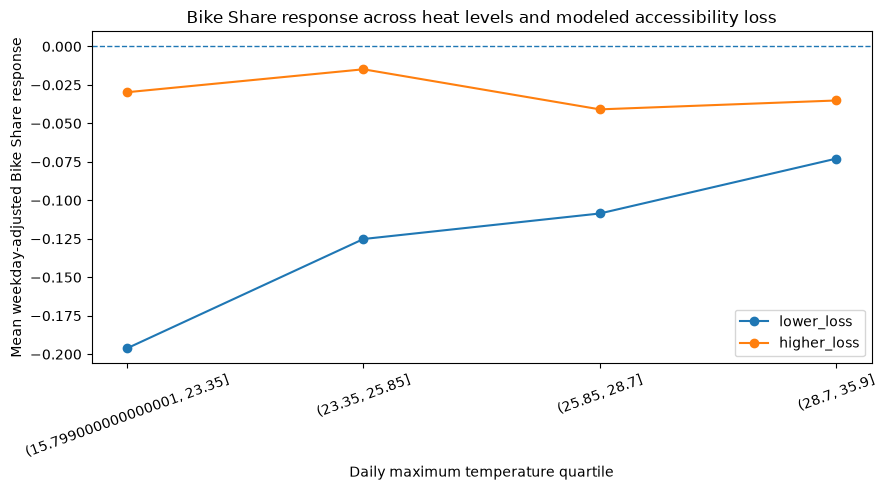

In [25]:
plot_df = (
    grouped_heat_response.copy()
)

plot_df[
    "temperature_group"
] = (
    plot_df[
        "tmax_bin"
    ].astype(str)
)

fig, ax = plt.subplots(
    figsize=(9, 5)
)

for group in [
    "lower_loss",
    "higher_loss",
]:

    subset = plot_df[
        plot_df[
            "modeled_loss_group"
        ] == group
    ]

    ax.plot(
        subset[
            "temperature_group"
        ],
        subset[
            "mean_response"
        ],
        marker="o",
        label=group,
    )

ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

ax.set_xlabel(
    "Daily maximum temperature quartile"
)

ax.set_ylabel(
    "Mean weekday-adjusted Bike Share response"
)

ax.set_title(
    "Bike Share response across heat levels and modeled accessibility loss"
)

ax.legend()

plt.xticks(
    rotation=20
)

plt.tight_layout()
plt.show()

## 26. Hot-day station-level average response

Aggregate each station across top-decile hot days.

In [26]:
hot_station_response = (
    panel[
        panel[
            "hot_top_decile"
        ]
    ]
    .groupby(
        "station_id_join"
    )
    .agg(
        hot_days=(
            "date",
            "nunique",
        ),
        mean_hot_response=(
            "weekday_adjusted_response",
            "mean",
        ),
        median_hot_response=(
            "weekday_adjusted_response",
            "median",
        ),
        modeled_absolute_loss_pct=(
            "modeled_absolute_loss_pct",
            "first",
        ),
        modeled_relative_loss_pct=(
            "modeled_relative_loss_pct",
            "first",
        ),
    )
    .reset_index()
)

display(
    hot_station_response.describe()
)

,hot_days,mean_hot_response,median_hot_response,modeled_absolute_loss_pct,modeled_relative_loss_pct
count,75.0,75.000000,75.000000,75.000000,75.000000
mean,10.0,-0.070313,-0.066042,25.327580,0.224062
std,0.0,0.317843,0.518186,5.451235,0.623229
min,10.0,-2.422610,-4.425256,14.809190,0.000000
25%,10.0,-0.066797,-0.062198,22.393402,0.000000
50%,10.0,-0.000855,0.000000,25.299866,0.000000
75%,10.0,0.016345,0.037022,27.592160,0.000000
max,10.0,0.149925,0.263057,40.385356,2.904486


## 27. Station-level hot-day correlation

In [27]:
station_corr_data = (
    hot_station_response[
        [
            "modeled_absolute_loss_pct",
            "mean_hot_response",
        ]
    ]
    .dropna()
)

hot_station_spearman = spearmanr(
    station_corr_data[
        "modeled_absolute_loss_pct"
    ],
    station_corr_data[
        "mean_hot_response"
    ],
)

print(
    "Station-level hot-day Spearman:",
    hot_station_spearman.statistic,
)

print(
    "p-value:",
    hot_station_spearman.pvalue,
)

Station-level hot-day Spearman: 0.09921388988948934
p-value: 0.3970629413892871


## 28. Map station-level hot-day response

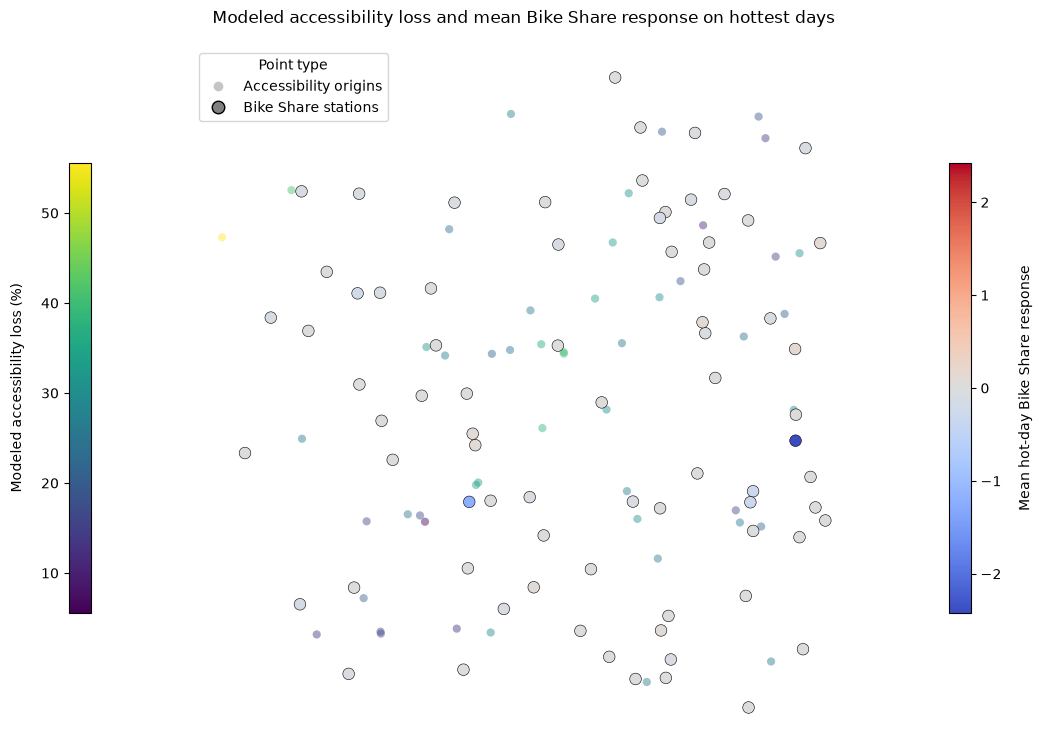

In [31]:
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D

fig, ax = plt.subplots(
    figsize=(10, 9)
)

fig.subplots_adjust(
    left=0.12,
    right=0.88,
)

# --------------------------------------------------
# 1. Modeled accessibility loss
# --------------------------------------------------

loss_min = origins[
    "absolute_loss_pct"
].min()

loss_max = origins[
    "absolute_loss_pct"
].max()

loss_norm = mpl.colors.Normalize(
    vmin=loss_min,
    vmax=loss_max,
)

loss_cmap = plt.get_cmap(
    "viridis"
)

origins.plot(
    ax=ax,
    column="absolute_loss_pct",
    cmap=loss_cmap,
    norm=loss_norm,
    markersize=35,
    alpha=0.45,
    edgecolor="none",
    legend=False,
)

# --------------------------------------------------
# 2. Mean Bike Share response on hot days
# --------------------------------------------------

response_max = max(
    abs(
        station_hot_map[
            "mean_hot_response"
        ].min()
    ),
    abs(
        station_hot_map[
            "mean_hot_response"
        ].max()
    ),
)

response_norm = mpl.colors.TwoSlopeNorm(
    vmin=-response_max,
    vcenter=0,
    vmax=response_max,
)

response_cmap = plt.get_cmap(
    "coolwarm"
)

station_hot_map.plot(
    ax=ax,
    column="mean_hot_response",
    cmap=response_cmap,
    norm=response_norm,
    markersize=70,
    edgecolor="black",
    linewidth=0.4,
    legend=False,
)

# --------------------------------------------------
# 3. LEFT colorbar = accessibility loss
# --------------------------------------------------

loss_sm = mpl.cm.ScalarMappable(
    norm=loss_norm,
    cmap=loss_cmap,
)

loss_sm.set_array([])

cax_left = fig.add_axes(
    [
        0.045,
        0.25,
        0.022,
        0.50,
    ]
)

cbar_left = fig.colorbar(
    loss_sm,
    cax=cax_left,
)

cbar_left.set_label(
    "Modeled accessibility loss (%)",
    labelpad=12,
)

cbar_left.ax.yaxis.set_ticks_position(
    "left"
)

cbar_left.ax.yaxis.set_label_position(
    "left"
)

# --------------------------------------------------
# 4. RIGHT colorbar = Bike Share response
# --------------------------------------------------

response_sm = mpl.cm.ScalarMappable(
    norm=response_norm,
    cmap=response_cmap,
)

response_sm.set_array([])

cax_right = fig.add_axes(
    [
        0.925,
        0.25,
        0.022,
        0.50,
    ]
)

cbar_right = fig.colorbar(
    response_sm,
    cax=cax_right,
)

cbar_right.set_label(
    "Mean hot-day Bike Share response",
    labelpad=12,
)

# --------------------------------------------------
# 5. Point-type legend
# --------------------------------------------------

point_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="None",
        markerfacecolor="gray",
        markeredgecolor="none",
        markersize=7,
        alpha=0.45,
        label="Accessibility origins",
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="None",
        markerfacecolor="gray",
        markeredgecolor="black",
        markersize=9,
        label="Bike Share stations",
    ),
]

ax.legend(
    handles=point_handles,
    loc="upper left",
    title="Point type",
)

ax.set_title(
    "Modeled accessibility loss and mean Bike Share response on hottest days"
)

ax.set_axis_off()

plt.show()

## 29. Optional simple regression with weekday fixed effects

If `statsmodels` is available, estimate an exploratory model:

\[
response_{sd}
=
β_1 Temp_d
+
β_2 Loss_s
+
β_3 Temp_d \times Loss_s
+
weekdayFE
+ ε
\]

This is not a causal model. It is a compact diagnostic of the interaction.

In [29]:
try:

    import statsmodels.formula.api as smf

    regression_df = panel[
        [
            "weekday_adjusted_response",
            "tmax_c",
            "modeled_absolute_loss_pct",
            "weekday",
            "station_id_join",
        ]
    ].dropna().copy()

    regression_df[
        "loss_centered"
    ] = (
        regression_df[
            "modeled_absolute_loss_pct"
        ]
        - regression_df[
            "modeled_absolute_loss_pct"
        ].mean()
    )

    regression_df[
        "temp_centered"
    ] = (
        regression_df[
            "tmax_c"
        ]
        - regression_df[
            "tmax_c"
        ].mean()
    )

    model = smf.ols(
        (
            "weekday_adjusted_response ~ "
            "temp_centered * loss_centered + "
            "C(weekday)"
        ),
        data=regression_df,
    ).fit(
        cov_type="cluster",
        cov_kwds={
            "groups": regression_df[
                "station_id_join"
            ]
        },
    )

    print(
        model.summary()
    )

except ImportError:

    print(
        "statsmodels is not installed; regression skipped."
    )

statsmodels is not installed; regression skipped.


## 30. Save panel outputs

In [34]:
panel_path = (
    PANEL_OUTPUTS
    / "toronto_summer2025_station_day_panel.parquet"
)

hot_station_path = (
    PANEL_OUTPUTS
    / "toronto_hot_day_station_response.csv"
)

grouped_path = (
    PANEL_OUTPUTS
    / "toronto_temperature_group_response.csv"
)
# Convert interval-category variables to portable strings
if "tmax_bin" in panel.columns:
    panel["tmax_bin"] = (
        panel["tmax_bin"]
        .astype(str)
    )

panel.to_parquet(
    panel_path,
    index=False,
)

hot_station_response.to_csv(
    hot_station_path,
    index=False,
)

grouped_heat_response.to_csv(
    grouped_path,
    index=False,
)

print("Saved:")
print("-", panel_path)
print("-", hot_station_path)
print("-", grouped_path)

Saved:
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/bikeshare_panel/toronto_summer2025_station_day_panel.parquet
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/bikeshare_panel/toronto_hot_day_station_response.csv
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/bikeshare_panel/toronto_temperature_group_response.csv


## 31. Final summary

In [36]:
panel_path = (
    PANEL_OUTPUTS
    / "toronto_summer2025_station_day_panel.parquet"
)

hot_station_path = (
    PANEL_OUTPUTS
    / "toronto_hot_day_station_response.csv"
)

grouped_path = (
    PANEL_OUTPUTS
    / "toronto_temperature_group_response.csv"
)

# --------------------------------------------------
# Make pandas categorical/interval fields
# parquet-safe
# --------------------------------------------------

panel_to_save = panel.copy()

for col in panel_to_save.columns:

    if isinstance(
        panel_to_save[col].dtype,
        pd.CategoricalDtype,
    ):

        panel_to_save[col] = (
            panel_to_save[col]
            .astype(str)
        )

# --------------------------------------------------
# Save
# --------------------------------------------------

panel_to_save.to_parquet(
    panel_path,
    index=False,
)

hot_station_response.to_csv(
    hot_station_path,
    index=False,
)

grouped_heat_response.to_csv(
    grouped_path,
    index=False,
)

print("Saved:")
print("-", panel_path)
print("-", hot_station_path)
print("-", grouped_path)

Saved:
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/bikeshare_panel/toronto_summer2025_station_day_panel.parquet
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/bikeshare_panel/toronto_hot_day_station_response.csv
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/bikeshare_panel/toronto_temperature_group_response.csv


## Interpretation

Notebook 10 moves the behavioral layer from a single-date comparison to a
repeated station-day design.

The most useful quantities are:

- overall temperature–ridership response;
- temperature × modeled-accessibility-loss interaction;
- difference between higher-loss and lower-loss stations across temperature bins;
- station-level mean response across the hottest summer days.

A stronger negative response at higher modeled-loss stations would be **consistent
with**, but would not prove, the hypothesis that thermal network impedance is
behaviorally meaningful.

Important limitations remain:

- thermal accessibility itself is currently modeled from one detailed SOLWEIG
  event rather than recomputed for every summer day;
- current GBFS station geometry is used;
- precipitation and other weather variables are not yet modeled explicitly;
- temporal autocorrelation and event effects are not fully controlled;
- λ remains uncalibrated.

If this panel produces a promising interaction, the next scientifically stronger
step is to model **multiple thermal days** rather than applying the same spatial
thermal-accessibility pattern across the whole summer.